# F1 : Risque de crédit en Allemagne

Notebook de scoring de crédit (jeu de données *German Credit*).

**Pour exécuter :** placer `german_credit_data.csv` dans `data/raw/` (ou laisser le notebook le chercher / le demander dans Colab), puis *Redémarrer et tout exécuter*.

In [1]:
# ============ CELLULE 1 : paramètres, configuration, chargement ============
# Remplissez ces informations personnelles (elles apparaissent dans le rapport) :
NOM = "À COMPLÉTER"
CODE_APOGEE = "À COMPLÉTER"
GROUPE = "À COMPLÉTER"
SOURCE_URL = "À COMPLÉTER (URL de la page de téléchargement du jeu de données)"
DATE_EXTRACTION = "À COMPLÉTER"
LICENCE = "À COMPLÉTER (voir la page de la source ; si rien n'est indiqué, l'écrire)"

import platform, zipfile, shutil, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt, sklearn
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

def md(texte):
    display(Markdown(texte))

GRAINE = 42
np.random.seed(GRAINE)
RACINE = Path(".")
CHEMIN_DONNEES = RACINE / "data" / "raw" / "german_credit_data.csv"
DOSSIER_FIGURES = RACINE / "figures"
CHEMIN_DONNEES.parent.mkdir(parents=True, exist_ok=True)
DOSSIER_FIGURES.mkdir(exist_ok=True)

if not CHEMIN_DONNEES.exists():                       # cherche le fichier déjà importé dans Colab
    for dossier in [Path("."), Path("/content")]:
        trouves = list(dossier.rglob("german_credit_data.csv"))
        if trouves:
            shutil.copy(trouves[0], CHEMIN_DONNEES); break
if not CHEMIN_DONNEES.exists():                       # sinon cherche une archive zip
    for z in list(Path(".").rglob("*.zip")) + list(Path("/content").rglob("*.zip")):
        with zipfile.ZipFile(z) as arc:
            if any(n.endswith("german_credit_data.csv") for n in arc.namelist()):
                arc.extractall(CHEMIN_DONNEES.parent); break
if not CHEMIN_DONNEES.exists():                       # sinon demande l'import
    from google.colab import files
    for nom in files.upload():
        if nom.endswith(".zip"):
            with zipfile.ZipFile(nom) as arc: arc.extractall(CHEMIN_DONNEES.parent)
        else:
            shutil.move(nom, CHEMIN_DONNEES.parent / nom)

df = pd.read_csv(CHEMIN_DONNEES)
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| matplotlib", matplotlib.__version__, "| scikit-learn", sklearn.__version__)

md(f"""
# F1 : Risque de crédit en Allemagne
**Nom et prénom :** {NOM}  |  **Code Apogée :** {CODE_APOGEE}  |  **Groupe :** {GROUPE}

## 1. Sujet et problématique
- **Intérêt du sujet :** un établissement de crédit doit accorder ou refuser un prêt à partir des informations du dossier. Accorder un prêt à un client qui ne rembourse pas coûte beaucoup plus cher que refuser un bon client. Un modèle de scoring aide l'analyste crédit à trier les dossiers et à fixer un seuil de décision cohérent avec ces coûts.
- **Problématique :** à partir des caractéristiques d'un dossier connues à la demande, peut-on prédire s'il sera mal remboursé, et quel seuil de décision minimise le coût moyen par dossier quand accorder un mauvais crédit coûte 5 fois plus que refuser un bon client ?
- **Objectif mesurable :** métrique principale = **coût moyen par dossier** (faux « bon » = 5, faux « mauvais » = 1). Référence = meilleure règle naïve (tout refuser, coût attendu 0,70). Test = 20 % des dossiers, stratifié, utilisé une seule fois. **Seuil de réussite : coût du modèle inférieur d'au moins 15 % à celui de la référence**, fixé avant tout résultat de test.
- **Nature du problème :** classification binaire, déséquilibrée (70 % / 30 %), à coûts asymétriques. L'exactitude seule serait trompeuse.
- **Algorithme principal :** n° 8, régression logistique.
""")

Python 3.12.3 | pandas 3.0.6 | numpy 2.5.4 | matplotlib 3.11.2 | scikit-learn 1.9.1



# F1 : Risque de crédit en Allemagne
**Nom et prénom :** À COMPLÉTER  |  **Code Apogée :** À COMPLÉTER  |  **Groupe :** À COMPLÉTER

## 1. Sujet et problématique
- **Intérêt du sujet :** un établissement de crédit doit accorder ou refuser un prêt à partir des informations du dossier. Accorder un prêt à un client qui ne rembourse pas coûte beaucoup plus cher que refuser un bon client. Un modèle de scoring aide l'analyste crédit à trier les dossiers et à fixer un seuil de décision cohérent avec ces coûts.
- **Problématique :** à partir des caractéristiques d'un dossier connues à la demande, peut-on prédire s'il sera mal remboursé, et quel seuil de décision minimise le coût moyen par dossier quand accorder un mauvais crédit coûte 5 fois plus que refuser un bon client ?
- **Objectif mesurable :** métrique principale = **coût moyen par dossier** (faux « bon » = 5, faux « mauvais » = 1). Référence = meilleure règle naïve (tout refuser, coût attendu 0,70). Test = 20 % des dossiers, stratifié, utilisé une seule fois. **Seuil de réussite : coût du modèle inférieur d'au moins 15 % à celui de la référence**, fixé avant tout résultat de test.
- **Nature du problème :** classification binaire, déséquilibrée (70 % / 30 %), à coûts asymétriques. L'exactitude seule serait trompeuse.
- **Algorithme principal :** n° 8, régression logistique.


## 2. Jeu de données

Dimensions (lignes, colonnes) : (1000, 21)
Doublons exacts : 0 | Valeurs manquantes : 0


,laufkont,laufzeit,moral,verw,hoehe,sparkont,beszeit,rate,famges,buerge,...,verm,alter,weitkred,wohn,bishkred,beruf,pers,telef,gastarb,kredit
0,1,18,4,2,1049,1,2,4,2,1,...,2,21,3,1,1,3,2,1,2,1
1,1,9,4,0,2799,1,3,2,3,1,...,1,36,3,1,2,3,1,1,2,1
2,2,12,2,9,841,2,4,2,2,1,...,1,23,3,1,1,2,2,1,2,1
3,1,12,4,0,2122,1,3,3,3,1,...,1,39,3,1,2,2,1,1,1,1
4,1,12,4,0,2171,1,3,4,3,1,...,2,38,1,2,2,2,2,1,1,1



**Lecture.** Le fichier contient 1000 dossiers et 21 colonnes, toutes numériques, sans valeur manquante ni doublon. Les variables qualitatives sont déjà codées en entiers : ces entiers sont des *catégories*, pas des quantités, ce qui impose un encodage à l'étape de préparation.

### 2.1 Description
- **Source et lien :** À COMPLÉTER (URL de la page de téléchargement du jeu de données)
- **Date d'extraction :** À COMPLÉTER
- **Licence :** À COMPLÉTER (voir la page de la source ; si rien n'est indiqué, l'écrire)
- **Taille :** 1000 observations, 20 variables explicatives et 1 variable cible. Données en coupe transversale, sans dimension temporelle : découpage aléatoire stratifié.
- **Unité d'observation :** un dossier de prêt accordé par une banque allemande, avec son issue (bien ou mal remboursé).
- **Variable cible :** `kredit` (1 = bon, 0 = mauvais), fournie. Je crée `defaut` = 1 si `kredit` = 0 pour que la classe positive soit le risque.
- **Adéquation :** le jeu contient les informations connues à la demande de prêt et l'issue du prêt, ce qui permet d'entraîner un modèle de scoring.
- **Limites :** 1 000 dossiers seulement (300 mauvais), estimations bruitées ; données anciennes, d'un seul pays, en Deutsche Marks ; seuls les prêts accordés sont observés (biais de sélection) ; la part de 30 % de mauvais est probablement échantillonnée et non représentative ; variables sensibles (`famges`, `gastarb`) discutables en pratique ; coûts 5:1 hérités de la documentation d'origine, ce sont des hypothèses et non des coûts observés.


### 2.2 Dictionnaire des variables

,Variable,Description,Type,Modalités / unité,Rôle,Manquants (%)
0,laufkont,Statut du compte courant,catégorielle ordinale,"1 = < 0 DM, 2 = 0 à 200 DM, 3 = >= 200 DM, 4 =...",explicative,0.0
1,laufzeit,Durée du crédit,numérique,mois,explicative,0.0
2,moral,Historique de crédit,catégorielle,"0 = aucun crédit / tout remboursé, 1 = tous le...",explicative,0.0
3,verw,Objet du crédit,catégorielle,"0 = voiture neuve, 1 = voiture d'occasion, 2 =...",explicative,0.0
4,hoehe,Montant du crédit,numérique,DM,explicative,0.0
5,sparkont,Épargne,catégorielle ordinale,"1 = < 100 DM, 2 = 100 à 500, 3 = 500 à 1000, 4...",explicative,0.0
6,beszeit,Ancienneté dans l'emploi actuel,catégorielle ordinale,"1 = sans emploi, 2 = < 1 an, 3 = 1 à 4 ans, 4 ...",explicative,0.0
7,rate,Taux d'effort (mensualité / revenu disponible),catégorielle ordinale,"1 à 4, le taux de mauvais augmente avec la val...",explicative,0.0
8,famges,Situation familiale et sexe,catégorielle,"1 = homme divorcé/séparé, 2 = femme (divorcée,...",explicative,0.0
9,buerge,Autres débiteurs / garants,catégorielle,"1 = aucun, 2 = co-demandeur, 3 = garant",explicative,0.0


**Lecture.** 3 variables sont réellement numériques (`laufzeit`, `hoehe`, `alter`) et 17 sont catégorielles ou ordinales codées en entiers. La variable `defaut` est la seule variable créée. Le sens des codes a été contrôlé par les effectifs et les taux de mauvais crédits ; les lignes « à confirmer » sont à vérifier dans la documentation de la source.

### 2.3 Variable cible et coûts

        effectif  proportion (%)
kredit                          
0            300            30.0
1            700            70.0

Coût moyen si on accepte tout : 1.50 | si on refuse tout : 0.70
Seuil théorique de refus P(mauvais) >= 0.167


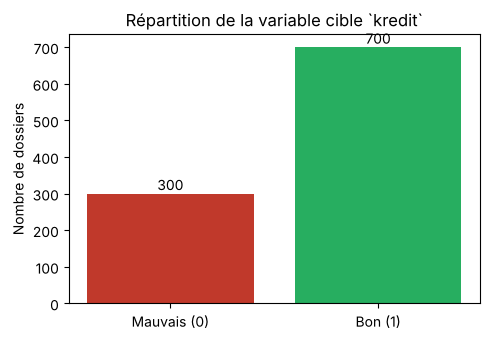


**Lecture.** 30 % des dossiers sont mauvais. Avec un coût de 5 pour un faux « bon » et de 1 pour un faux « mauvais », « tout accepter » coûte 1.50 par dossier et « tout refuser » 0.70. **La meilleure règle naïve est donc de tout refuser (0.70)** : c'est la référence. La théorie indique qu'il faut refuser dès que P(mauvais) dépasse 1/6 (≈ 0,167), très en dessous de 0,5 : le seuil de décision fait partie du livrable.


In [2]:
# ============ CELLULE 2 : section 2, jeu de données ============
md("## 2. Jeu de données")
print("Dimensions (lignes, colonnes) :", df.shape)
print("Doublons exacts :", int(df.duplicated().sum()), "| Valeurs manquantes :", int(df.isna().sum().sum()))
display(df.head())
md(f"""
**Lecture.** Le fichier contient {df.shape[0]} dossiers et {df.shape[1]} colonnes, toutes numériques, sans valeur manquante ni doublon. Les variables qualitatives sont déjà codées en entiers : ces entiers sont des *catégories*, pas des quantités, ce qui impose un encodage à l'étape de préparation.

### 2.1 Description
- **Source et lien :** {SOURCE_URL}
- **Date d'extraction :** {DATE_EXTRACTION}
- **Licence :** {LICENCE}
- **Taille :** {df.shape[0]} observations, 20 variables explicatives et 1 variable cible. Données en coupe transversale, sans dimension temporelle : découpage aléatoire stratifié.
- **Unité d'observation :** un dossier de prêt accordé par une banque allemande, avec son issue (bien ou mal remboursé).
- **Variable cible :** `kredit` (1 = bon, 0 = mauvais), fournie. Je crée `defaut` = 1 si `kredit` = 0 pour que la classe positive soit le risque.
- **Adéquation :** le jeu contient les informations connues à la demande de prêt et l'issue du prêt, ce qui permet d'entraîner un modèle de scoring.
- **Limites :** 1 000 dossiers seulement (300 mauvais), estimations bruitées ; données anciennes, d'un seul pays, en Deutsche Marks ; seuls les prêts accordés sont observés (biais de sélection) ; la part de 30 % de mauvais est probablement échantillonnée et non représentative ; variables sensibles (`famges`, `gastarb`) discutables en pratique ; coûts 5:1 hérités de la documentation d'origine, ce sont des hypothèses et non des coûts observés.
""")

md("### 2.2 Dictionnaire des variables")
dico = pd.DataFrame([
 ("laufkont", "Statut du compte courant", "catégorielle ordinale", "1 = < 0 DM, 2 = 0 à 200 DM, 3 = >= 200 DM, 4 = pas de compte courant", "explicative"),
 ("laufzeit", "Durée du crédit", "numérique", "mois", "explicative"),
 ("moral", "Historique de crédit", "catégorielle", "0 = aucun crédit / tout remboursé, 1 = tous les crédits de cette banque remboursés, 2 = crédits en cours remboursés normalement, 3 = retard de paiement passé, 4 = compte critique / crédits ailleurs", "explicative"),
 ("verw", "Objet du crédit", "catégorielle", "0 = voiture neuve, 1 = voiture d'occasion, 2 = meubles, 3 = radio/TV, 4 = électroménager, 5 = réparations, 6 = formation, 8 = reconversion, 9 = entreprise, 10 = autre", "explicative"),
 ("hoehe", "Montant du crédit", "numérique", "DM", "explicative"),
 ("sparkont", "Épargne", "catégorielle ordinale", "1 = < 100 DM, 2 = 100 à 500, 3 = 500 à 1000, 4 = >= 1000 DM, 5 = inconnue / pas d'épargne", "explicative"),
 ("beszeit", "Ancienneté dans l'emploi actuel", "catégorielle ordinale", "1 = sans emploi, 2 = < 1 an, 3 = 1 à 4 ans, 4 = 4 à 7 ans, 5 = >= 7 ans", "explicative"),
 ("rate", "Taux d'effort (mensualité / revenu disponible)", "catégorielle ordinale", "1 à 4, le taux de mauvais augmente avec la valeur ; à confirmer dans la documentation", "explicative"),
 ("famges", "Situation familiale et sexe", "catégorielle", "1 = homme divorcé/séparé, 2 = femme (divorcée, séparée ou mariée), 3 = homme célibataire, 4 = homme marié/veuf", "explicative"),
 ("buerge", "Autres débiteurs / garants", "catégorielle", "1 = aucun, 2 = co-demandeur, 3 = garant", "explicative"),
 ("wohnzeit", "Ancienneté dans le logement actuel", "catégorielle ordinale", "1 = < 1 an, 2 = 1 à 4, 3 = 4 à 7, 4 = >= 7 ans", "explicative"),
 ("verm", "Patrimoine le plus important", "catégorielle", "1 = immobilier, 2 = assurance-vie / épargne-logement, 3 = voiture ou autre, 4 = inconnu / aucun", "explicative"),
 ("alter", "Âge du demandeur", "numérique", "années", "explicative"),
 ("weitkred", "Autres crédits en cours", "catégorielle", "1 = banque, 2 = magasins, 3 = aucun", "explicative"),
 ("wohn", "Type de logement", "catégorielle", "1 = locataire, 2 = propriétaire, 3 = logé gratuitement", "explicative"),
 ("bishkred", "Nombre de crédits à cette banque", "catégorielle ordinale", "1 à 4 (codes ordinaux)", "explicative"),
 ("beruf", "Qualification professionnelle", "catégorielle ordinale", "1 = non qualifié non résident ... 4 = cadre / indépendant", "explicative"),
 ("pers", "Personnes à charge", "binaire", "deux modalités ; à confirmer dans la documentation", "explicative"),
 ("telef", "Téléphone au nom du client", "binaire", "1 = non, 2 = oui", "explicative"),
 ("gastarb", "Travailleur étranger", "binaire", "deux modalités (37 et 963 dossiers) ; à confirmer dans la documentation", "explicative"),
 ("kredit", "Qualité du crédit", "binaire", "1 = bon, 0 = mauvais", "cible"),
 ("defaut", "Mauvais crédit (créée)", "binaire", "defaut = 1 si kredit = 0, sinon 0", "cible utilisée"),
], columns=["Variable", "Description", "Type", "Modalités / unité", "Rôle"])
df["defaut"] = (df["kredit"] == 0).astype(int)
dico["Manquants (%)"] = dico["Variable"].map(lambda v: round(100 * df[v].isna().mean(), 1))
assert set(dico["Variable"]) == set(df.columns)
display(dico)
md("**Lecture.** 3 variables sont réellement numériques (`laufzeit`, `hoehe`, `alter`) et 17 sont catégorielles ou ordinales codées en entiers. La variable `defaut` est la seule variable créée. Le sens des codes a été contrôlé par les effectifs et les taux de mauvais crédits ; les lignes « à confirmer » sont à vérifier dans la documentation de la source.")

md("### 2.3 Variable cible et coûts")
COUT_FAUX_BON, COUT_FAUX_MAUVAIS = 5, 1
effectifs = df["kredit"].value_counts().sort_index()
part_mauvais = df["defaut"].mean()
cout_tout_accepter = COUT_FAUX_BON * part_mauvais
cout_tout_refuser = COUT_FAUX_MAUVAIS * (1 - part_mauvais)
print(pd.DataFrame({"effectif": effectifs, "proportion (%)": (100 * effectifs / len(df)).round(1)}))
print(f"\nCoût moyen si on accepte tout : {cout_tout_accepter:.2f} | si on refuse tout : {cout_tout_refuser:.2f}")
print(f"Seuil théorique de refus P(mauvais) >= {COUT_FAUX_MAUVAIS/(COUT_FAUX_BON+COUT_FAUX_MAUVAIS):.3f}")
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["Mauvais (0)", "Bon (1)"], effectifs.values, color=["#c0392b", "#27ae60"])
for i, v in enumerate(effectifs.values): ax.text(i, v + 10, str(v), ha="center")
ax.set_title("Répartition de la variable cible `kredit`"); ax.set_ylabel("Nombre de dossiers")
fig.tight_layout(); fig.savefig(DOSSIER_FIGURES / "01_repartition_cible.png", dpi=150); plt.show()
md(f"""
**Lecture.** {100*part_mauvais:.0f} % des dossiers sont mauvais. Avec un coût de {COUT_FAUX_BON} pour un faux « bon » et de {COUT_FAUX_MAUVAIS} pour un faux « mauvais », « tout accepter » coûte {cout_tout_accepter:.2f} par dossier et « tout refuser » {cout_tout_refuser:.2f}. **La meilleure règle naïve est donc de tout refuser ({cout_tout_refuser:.2f})** : c'est la référence. La théorie indique qu'il faut refuser dès que P(mauvais) dépasse 1/6 (≈ 0,167), très en dessous de 0,5 : le seuil de décision fait partie du livrable.
""")

## 3. Exploration

,laufzeit,hoehe,alter
count,1000.0,1000.0,1000.0
mean,20.9,3271.2,35.5
std,12.1,2822.8,11.4
min,4.0,250.0,19.0
25%,12.0,1365.5,27.0
50%,18.0,2319.5,33.0
75%,24.0,3972.2,42.0
max,72.0,18424.0,75.0



**Qualité des données.** Aucune valeur manquante, aucun doublon. 72 montants (7.2 %) dépassent 7882 DM selon la règle de 1,5 × IQR, avec un maximum de 18424 DM. Ce sont de vrais gros prêts, pas des erreurs : **je les conserve**. Leur asymétrie sera réduite par une transformation logarithmique à l'étape 4.


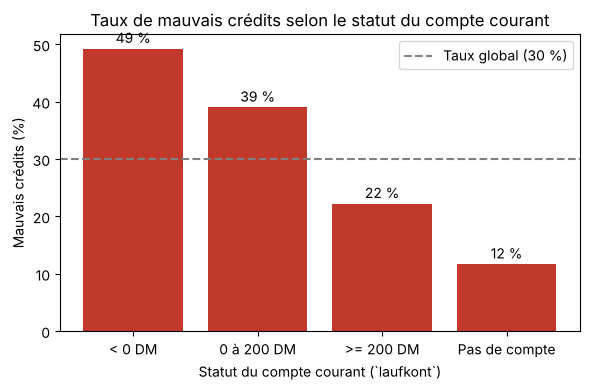


**Interprétation du graphique 1.** Le taux de mauvais crédits va de 49 % (< 0 DM) à 12 % (Pas de compte), contre 30 % en moyenne : le statut du compte est très discriminant, et je m'attends à ce qu'il pèse beaucoup dans le modèle. Corrélation n'est pas causalité : « pas de compte » peut refléter un type de client particulier.


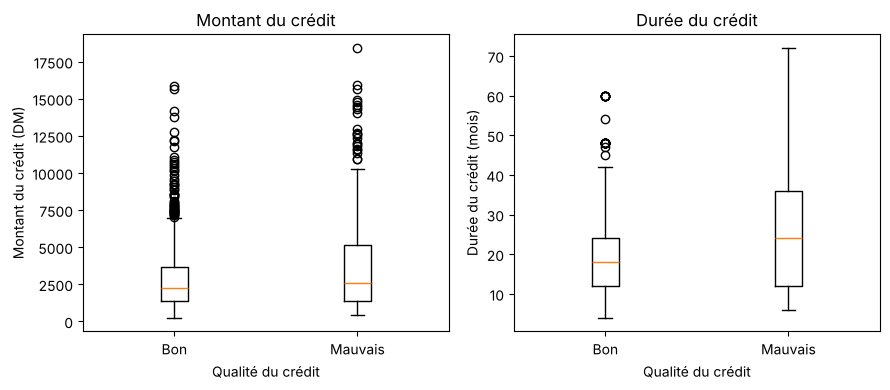


**Interprétation du graphique 2.** Les mauvais crédits portent sur des durées plus longues (médiane de 24 mois contre 18) et des montants plus élevés (2574 DM contre 2244). Les distributions se chevauchent beaucoup : ces deux variables seules ne suffisent pas à séparer les classes. Les points extrêmes confirment l'asymétrie des montants.


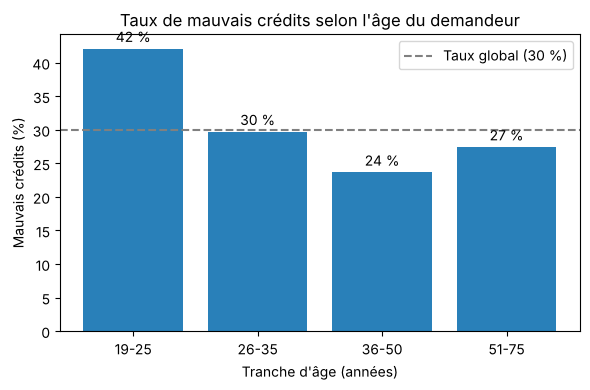


**Interprétation du graphique 3.** Les 19-25 ans présentent 42 % de mauvais crédits, contre 24 % pour les 36-50 ans. Le taux remonte légèrement après 50 ans (27 %) : la relation n'est pas strictement décroissante, l'âge est une variable utile mais non linéaire.


In [3]:
# ============ CELLULE 3 : section 3, exploration ============
md("## 3. Exploration")
num = ["laufzeit", "hoehe", "alter"]
display(df[num].describe().round(1))
q1, q3 = df["hoehe"].quantile([0.25, 0.75])
borne = q3 + 1.5 * (q3 - q1)
n_atyp = int((df["hoehe"] > borne).sum())
md(f"""
**Qualité des données.** Aucune valeur manquante, aucun doublon. {n_atyp} montants ({100*n_atyp/len(df):.1f} %) dépassent {borne:.0f} DM selon la règle de 1,5 × IQR, avec un maximum de {df['hoehe'].max()} DM. Ce sont de vrais gros prêts, pas des erreurs : **je les conserve**. Leur asymétrie sera réduite par une transformation logarithmique à l'étape 4.
""")

# Graphique 1
taux_cpt = df.groupby("laufkont")["defaut"].mean() * 100
etiq = {1: "< 0 DM", 2: "0 à 200 DM", 3: ">= 200 DM", 4: "Pas de compte"}
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar([etiq[k] for k in taux_cpt.index], taux_cpt.values, color="#c0392b")
ax.axhline(30, color="gray", ls="--", label="Taux global (30 %)")
for i, v in enumerate(taux_cpt.values): ax.text(i, v + 1, f"{v:.0f} %", ha="center")
ax.set_title("Taux de mauvais crédits selon le statut du compte courant")
ax.set_xlabel("Statut du compte courant (`laufkont`)"); ax.set_ylabel("Mauvais crédits (%)")
ax.legend(); fig.tight_layout()
fig.savefig(DOSSIER_FIGURES / "02_taux_defaut_compte.png", dpi=150); plt.show()
md(f"""
**Interprétation du graphique 1.** Le taux de mauvais crédits va de {taux_cpt.max():.0f} % ({etiq[taux_cpt.idxmax()]}) à {taux_cpt.min():.0f} % ({etiq[taux_cpt.idxmin()]}), contre 30 % en moyenne : le statut du compte est très discriminant, et je m'attends à ce qu'il pèse beaucoup dans le modèle. Corrélation n'est pas causalité : « pas de compte » peut refléter un type de client particulier.
""")

# Graphique 2
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, var, titre, unite in [(axes[0], "hoehe", "Montant du crédit", "DM"), (axes[1], "laufzeit", "Durée du crédit", "mois")]:
    ax.boxplot([df.loc[df["defaut"] == 0, var], df.loc[df["defaut"] == 1, var]])
    ax.set_xticks([1, 2], ["Bon", "Mauvais"])
    ax.set_title(titre); ax.set_xlabel("Qualité du crédit"); ax.set_ylabel(f"{titre} ({unite})")
fig.tight_layout(); fig.savefig(DOSSIER_FIGURES / "03_montant_duree.png", dpi=150); plt.show()
med = df.groupby("defaut")[["hoehe", "laufzeit"]].median()
md(f"""
**Interprétation du graphique 2.** Les mauvais crédits portent sur des durées plus longues (médiane de {med.loc[1,'laufzeit']:.0f} mois contre {med.loc[0,'laufzeit']:.0f}) et des montants plus élevés ({med.loc[1,'hoehe']:.0f} DM contre {med.loc[0,'hoehe']:.0f}). Les distributions se chevauchent beaucoup : ces deux variables seules ne suffisent pas à séparer les classes. Les points extrêmes confirment l'asymétrie des montants.
""")

# Graphique 3
df["tranche_age"] = pd.cut(df["alter"], [18, 25, 35, 50, 80], labels=["19-25", "26-35", "36-50", "51-75"])
taux_age = df.groupby("tranche_age", observed=True)["defaut"].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(taux_age.index.astype(str), taux_age["mean"] * 100, color="#2980b9")
ax.axhline(30, color="gray", ls="--", label="Taux global (30 %)")
for i, v in enumerate(taux_age["mean"] * 100): ax.text(i, v + 1, f"{v:.0f} %", ha="center")
ax.set_title("Taux de mauvais crédits selon l'âge du demandeur")
ax.set_xlabel("Tranche d'âge (années)"); ax.set_ylabel("Mauvais crédits (%)")
ax.legend(); fig.tight_layout()
fig.savefig(DOSSIER_FIGURES / "04_taux_defaut_age.png", dpi=150); plt.show()
md(f"""
**Interprétation du graphique 3.** Les 19-25 ans présentent {100*taux_age.loc['19-25','mean']:.0f} % de mauvais crédits, contre {100*taux_age.loc['36-50','mean']:.0f} % pour les 36-50 ans. Le taux remonte légèrement après 50 ans ({100*taux_age.loc['51-75','mean']:.0f} %) : la relation n'est pas strictement décroissante, l'âge est une variable utile mais non linéaire.
""")

In [4]:
# ============ CELLULE 4 : section 4, préparation ============
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer

md("## 4. Préparation")
X = df.drop(columns=["kredit", "defaut", "tranche_age"])
y = df["defaut"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=GRAINE)
print("Apprentissage :", X_train.shape, "| Test :", X_test.shape)
print("Part de mauvais - apprentissage :", round(y_train.mean(), 3), "| test :", round(y_test.mean(), 3))

colonnes_num = ["laufzeit", "hoehe", "alter"]
colonnes_cat = [c for c in X.columns if c not in colonnes_num]
preparation = ColumnTransformer([
    ("num", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                      ("echelle", StandardScaler())]), colonnes_num),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False), colonnes_cat),
])
preparation.fit(X_train)
Z_train = preparation.transform(X_train); Z_test = preparation.transform(X_test)
print("Variables après préparation :", Z_train.shape[1])
print("Apprentissage, moyenne / écart-type :", Z_train[:, :3].mean(0).round(2), Z_train[:, :3].std(0).round(2))
print("Test, moyenne / écart-type          :", Z_test[:, :3].mean(0).round(2), Z_test[:, :3].std(0).round(2))
md(f"""
**Décisions et justifications.**
- Découpage 80/20 **avant toute transformation**, stratifié ({X_train.shape[0]} dossiers d'apprentissage, {X_test.shape[0]} de test, {100*y_train.mean():.0f} % de mauvais dans chacun), graine {GRAINE}. Les données n'étant pas datées, un découpage aléatoire est correct.
- `hoehe` subit un `log1p` pour réduire l'asymétrie, puis les 3 variables numériques sont standardisées, car la régression logistique est sensible à l'échelle.
- Les {len(colonnes_cat)} variables codées en entiers sont encodées en *one-hot* : ce sont des catégories, pas des quantités. On obtient {Z_train.shape[1]} variables.
- Le `fit` du préprocesseur est fait sur `X_train` **seulement** : les 3 variables numériques sont centrées-réduites (moyenne 0, écart-type 1) sur l'apprentissage, mais pas exactement sur le test, ce qui prouve qu'aucune information du test n'a servi.
- Les transformations sont placées dans un `Pipeline`, donc réajustées dans chaque pli de validation croisée. Aucune variable dérivée n'est créée, sauf la cible `defaut`.
""")

## 4. Préparation

Apprentissage : (800, 20) | Test : (200, 20)
Part de mauvais - apprentissage : 0.3 | test : 0.3
Variables après préparation : 68
Apprentissage, moyenne / écart-type : [ 0. -0. -0.] [1. 1. 1.]
Test, moyenne / écart-type          : [ 0.01  0.08 -0.09] [0.96 0.99 1.09]



**Décisions et justifications.**
- Découpage 80/20 **avant toute transformation**, stratifié (800 dossiers d'apprentissage, 200 de test, 30 % de mauvais dans chacun), graine 42. Les données n'étant pas datées, un découpage aléatoire est correct.
- `hoehe` subit un `log1p` pour réduire l'asymétrie, puis les 3 variables numériques sont standardisées, car la régression logistique est sensible à l'échelle.
- Les 17 variables codées en entiers sont encodées en *one-hot* : ce sont des catégories, pas des quantités. On obtient 68 variables.
- Le `fit` du préprocesseur est fait sur `X_train` **seulement** : les 3 variables numériques sont centrées-réduites (moyenne 0, écart-type 1) sur l'apprentissage, mais pas exactement sur le test, ce qui prouve qu'aucune information du test n'a servi.
- Les transformations sont placées dans un `Pipeline`, donc réajustées dans chaque pli de validation croisée. Aucune variable dérivée n'est créée, sauf la cible `defaut`.



## 5. Algorithme : régression logistique (n° 8)
**Choix.** Elle fournit directement une probabilité P(mauvais), nécessaire pour fixer un seuil à coûts asymétriques ; elle est interprétable et adaptée à 800 dossiers d'apprentissage. **Alternative non retenue :** le Gradient Boosting (n° 14), plus flexible mais plus exposé au surapprentissage sur si peu de données et moins lisible.

**Principe.** Le modèle calcule un score linéaire z = w·x + b puis P(mauvais | x) = 1 / (1 + e^(−z)). Ici x est le vecteur des variables préparées, w les coefficients appris et b l'ordonnée à l'origine. L'apprentissage minimise la perte logarithmique avec pénalité L2 : Σ −[y·ln p + (1−y)·ln(1−p)] + (1/(2C))·‖w‖². **Paramètres appris :** w et b. **Hyperparamètres :** C, l'inverse de la régularisation (C petit = coefficients très contraints, risque de sous-apprentissage ; C grand = peu de contrainte, risque de surapprentissage), et le seuil s de refus (on refuse si P(mauvais) ≥ s).

## 6. Protocole expérimental
Découpage 80/20 stratifié (graine 42). Référence naïve : « tout refuser ». Réglage de C et du seuil par validation croisée stratifiée à 5 plis **sur l'apprentissage seulement**. Métrique principale : coût moyen par dossier. Métriques secondaires : AUC et exactitude équilibrée, robustes au déséquilibre. Le test n'est utilisé qu'une fois, à la fin.


Référence 'tout refuser' : 0.700 | 'tout accepter' : 1.500 (apprentissage)
Seuil de réussite fixé : coût test <= 0.595 (15 % sous 0,70)


,C,seuil,cout_validation,ecart_type_plis,cout_apprentissage,AUC_validation
0,0.01,0.24,0.542,0.088,0.516,0.776
1,0.03,0.20,0.534,0.094,0.491,0.786
2,0.10,0.16,0.539,0.090,0.479,0.786
3,0.30,0.14,0.529,0.100,0.478,0.782
4,1.00,0.12,0.540,0.104,0.472,0.776


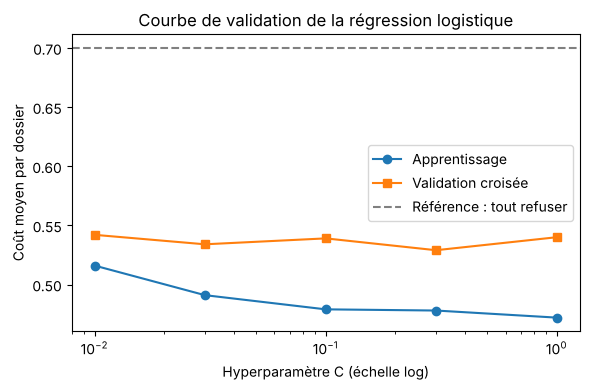

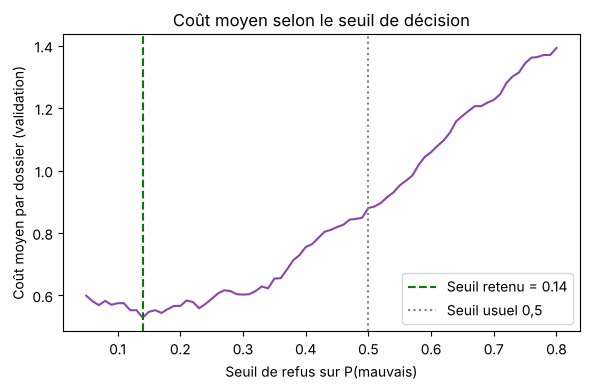


**Interprétation.** Configurations essayées : 5 valeurs de C × 76 seuils = 380, toutes évaluées en validation croisée sur l'apprentissage. Le coût de validation reste compris entre 0.53 et 0.54 selon C, loin de la référence (0.70). Le coût d'apprentissage baisse quand C augmente (0.52 à 0.47) alors que celui de validation ne suit pas : début de surapprentissage pour les grands C. L'écart-type entre plis (0.10 pour le C retenu) est du même ordre que les différences entre valeurs de C : ces valeurs sont difficiles à distinguer.

**Choix : C = 0.3, seuil de refus = 0.14** (seuil théorique = 0,167). Le seuil usuel de 0,5 donnerait un coût de validation de 0.88, pire que la référence « tout refuser » (0.70) : avec ces coûts, un seuil de 0,5 serait une erreur.


In [5]:
# ============ CELLULE 5 : sections 5 et 6, algorithme et protocole ============
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score, balanced_accuracy_score

md("""
## 5. Algorithme : régression logistique (n° 8)
**Choix.** Elle fournit directement une probabilité P(mauvais), nécessaire pour fixer un seuil à coûts asymétriques ; elle est interprétable et adaptée à 800 dossiers d'apprentissage. **Alternative non retenue :** le Gradient Boosting (n° 14), plus flexible mais plus exposé au surapprentissage sur si peu de données et moins lisible.

**Principe.** Le modèle calcule un score linéaire z = w·x + b puis P(mauvais | x) = 1 / (1 + e^(−z)). Ici x est le vecteur des variables préparées, w les coefficients appris et b l'ordonnée à l'origine. L'apprentissage minimise la perte logarithmique avec pénalité L2 : Σ −[y·ln p + (1−y)·ln(1−p)] + (1/(2C))·‖w‖². **Paramètres appris :** w et b. **Hyperparamètres :** C, l'inverse de la régularisation (C petit = coefficients très contraints, risque de sous-apprentissage ; C grand = peu de contrainte, risque de surapprentissage), et le seuil s de refus (on refuse si P(mauvais) ≥ s).

## 6. Protocole expérimental
Découpage 80/20 stratifié (graine 42). Référence naïve : « tout refuser ». Réglage de C et du seuil par validation croisée stratifiée à 5 plis **sur l'apprentissage seulement**. Métrique principale : coût moyen par dossier. Métriques secondaires : AUC et exactitude équilibrée, robustes au déséquilibre. Le test n'est utilisé qu'une fois, à la fin.
""")

def cout_moyen(y_vrai, y_pred):
    """y = 1 : mauvais crédit ; prédire 1 = refuser, prédire 0 = accepter."""
    y_vrai, y_pred = np.asarray(y_vrai), np.asarray(y_pred)
    faux_bons = ((y_vrai == 1) & (y_pred == 0)).sum()
    faux_mauvais = ((y_vrai == 0) & (y_pred == 1)).sum()
    return (COUT_FAUX_BON * faux_bons + COUT_FAUX_MAUVAIS * faux_mauvais) / len(y_vrai)

ref_refuser = cout_moyen(y_train, np.ones(len(y_train)))
ref_accepter = cout_moyen(y_train, np.zeros(len(y_train)))
print(f"Référence 'tout refuser' : {ref_refuser:.3f} | 'tout accepter' : {ref_accepter:.3f} (apprentissage)")
SEUIL_REUSSITE = 0.85 * 0.70
print(f"Seuil de réussite fixé : coût test <= {SEUIL_REUSSITE:.3f} (15 % sous 0,70)")

VALEURS_C = [0.01, 0.03, 0.1, 0.3, 1.0]
SEUILS = np.round(np.arange(0.05, 0.81, 0.01), 2)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE)
Xtr = X_train.reset_index(drop=True); ytr = y_train.reset_index(drop=True)

def modele(C):
    return Pipeline([("prep", clone(preparation)),
                     ("clf", LogisticRegression(C=C, max_iter=2000, random_state=GRAINE))])

def proba_validation(C, Xa, ya):
    oof = np.zeros(len(ya)); plis = []
    for i_tr, i_va in cv.split(Xa, ya):
        m = modele(C).fit(Xa.iloc[i_tr], ya.iloc[i_tr])
        oof[i_va] = m.predict_proba(Xa.iloc[i_va])[:, 1]
        plis.append((i_tr, i_va, m.predict_proba(Xa.iloc[i_tr])[:, 1]))
    return oof, plis

def meilleur_seuil(proba, ya):
    couts = [cout_moyen(ya, proba >= s) for s in SEUILS]
    return SEUILS[int(np.argmin(couts))], min(couts)

resultats = []
for C in VALEURS_C:
    oof, plis = proba_validation(C, Xtr, ytr)
    s, c_val = meilleur_seuil(oof, ytr)
    c_plis = [cout_moyen(ytr.iloc[i_va], oof[i_va] >= s) for _, i_va, _ in plis]
    c_app = np.mean([cout_moyen(ytr.iloc[i_tr], p >= s) for i_tr, _, p in plis])
    resultats.append({"C": C, "seuil": s, "cout_validation": c_val, "ecart_type_plis": np.std(c_plis),
                      "cout_apprentissage": c_app, "AUC_validation": roc_auc_score(ytr, oof)})
res = pd.DataFrame(resultats).round(3)
display(res)
best = res.loc[res["cout_validation"].idxmin()]
C_OPT, SEUIL_OPT = float(best["C"]), float(best["seuil"])
N_CONFIGS = len(VALEURS_C) * len(SEUILS)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(res["C"], res["cout_apprentissage"], "o-", label="Apprentissage")
ax.plot(res["C"], res["cout_validation"], "s-", label="Validation croisée")
ax.axhline(ref_refuser, color="gray", ls="--", label="Référence : tout refuser")
ax.set_xscale("log"); ax.set_xlabel("Hyperparamètre C (échelle log)"); ax.set_ylabel("Coût moyen par dossier")
ax.set_title("Courbe de validation de la régression logistique"); ax.legend(); fig.tight_layout()
fig.savefig(DOSSIER_FIGURES / "05_courbe_validation.png", dpi=150); plt.show()

oof_opt, _ = proba_validation(C_OPT, Xtr, ytr)
couts_seuil = [cout_moyen(ytr, oof_opt >= s) for s in SEUILS]
cout_val_05 = cout_moyen(ytr, oof_opt >= 0.5)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(SEUILS, couts_seuil, color="#8e44ad")
ax.axvline(SEUIL_OPT, color="green", ls="--", label=f"Seuil retenu = {SEUIL_OPT}")
ax.axvline(0.5, color="gray", ls=":", label="Seuil usuel 0,5")
ax.set_xlabel("Seuil de refus sur P(mauvais)"); ax.set_ylabel("Coût moyen par dossier (validation)")
ax.set_title("Coût moyen selon le seuil de décision"); ax.legend(); fig.tight_layout()
fig.savefig(DOSSIER_FIGURES / "06_cout_selon_seuil.png", dpi=150); plt.show()

md(f"""
**Interprétation.** Configurations essayées : {len(VALEURS_C)} valeurs de C × {len(SEUILS)} seuils = {N_CONFIGS}, toutes évaluées en validation croisée sur l'apprentissage. Le coût de validation reste compris entre {res['cout_validation'].min():.2f} et {res['cout_validation'].max():.2f} selon C, loin de la référence ({ref_refuser:.2f}). Le coût d'apprentissage baisse quand C augmente ({res['cout_apprentissage'].iloc[0]:.2f} à {res['cout_apprentissage'].iloc[-1]:.2f}) alors que celui de validation ne suit pas : début de surapprentissage pour les grands C. L'écart-type entre plis ({best['ecart_type_plis']:.2f} pour le C retenu) est du même ordre que les différences entre valeurs de C : ces valeurs sont difficiles à distinguer.

**Choix : C = {C_OPT}, seuil de refus = {SEUIL_OPT}** (seuil théorique = 0,167). Le seuil usuel de 0,5 donnerait un coût de validation de {cout_val_05:.2f}, {'pire' if cout_val_05 > ref_refuser else 'comparable'} que la référence « tout refuser » ({ref_refuser:.2f}) : avec ces coûts, un seuil de 0,5 serait une erreur.
""")

## 7. Résultats

,Tout refuser (référence),Modèle (seuil retenu),"Modèle (seuil 0,5)"
Coût moyen par dossier,0.7,0.640,0.93
Exactitude équilibrée,0.5,0.629,0.66
AUC,NaN,0.750,0.75


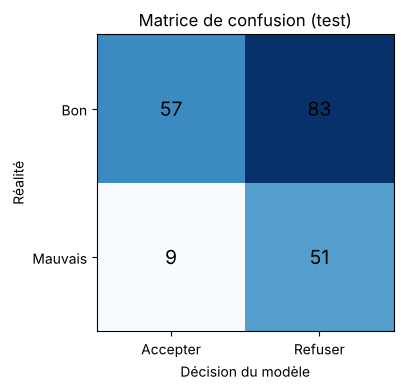

Mauvais crédits acceptés à tort (les 5 moins bien détectés) :


,laufkont,laufzeit,hoehe,alter,moral,proba
949,4,12,797,33,4,0.031
717,4,24,4591,54,2,0.059
765,4,9,1478,22,2,0.076
896,4,21,2580,41,3,0.094
953,4,48,11590,24,4,0.102


,size,mean
laufkont,,
1,57,0.53
2,48,0.48
3,17,0.53
4,78,0.38


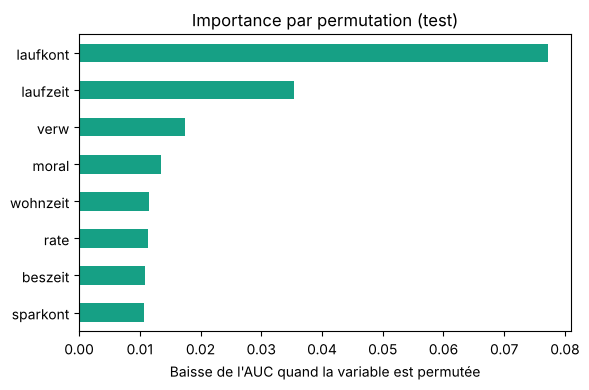

,laufkont,laufzeit,hoehe,alter,moral,proba,decision,réalité
474,3,36,4473,31,2,0.410,Refuser,Bon
322,4,11,2142,28,2,0.036,Accepter,Bon
409,4,42,7166,29,2,0.102,Accepter,Bon
198,4,12,2141,35,2,0.068,Accepter,Bon
260,4,15,2708,27,2,0.239,Refuser,Bon



**Interprétation.**
- **Comparaison à la référence.** Sur le test, le modèle coûte **0.640** par dossier contre 0.700 pour « tout refuser », soit une réduction de **8.6 %** pour un objectif de 15 %. **Objectif non atteint sur ce découpage.** L'AUC est de 0.75. Avec le seuil de 0,5, le coût serait de 0.93 : le seuil choisi selon les coûts est indispensable.
- **Erreurs.** Le modèle détecte 51 mauvais crédits sur 60 (rappel 0.85) mais seulement 38 % de ses refus sont justifiés : 83 bons clients sont refusés (coût 83) et 9 mauvais sont acceptés (coût 45). Il refuse 67 % des demandes : c'est la conséquence du rapport de coûts 5:1 et d'un signal modéré. Parmi les mauvais crédits acceptés à tort, 78 % viennent de clients sans compte courant, la catégorie réputée la plus sûre (donc la plus difficile à repérer).
- **Surapprentissage.** Le coût vaut 0.486 en apprentissage et 0.640 en test : l'écart de 0.154 indique un surapprentissage modéré, aggravé par un test de seulement 200 dossiers.
- **Variables.** Les variables les plus importantes par permutation sont `laufkont` (Statut du compte courant), `laufzeit` (Durée du crédit) et `verw` (Objet du crédit). Il s'agit d'associations statistiques, pas de causes.
- **Stabilité.** Sur 10 découpages différents (avec C fixé, seuil réajusté à chaque fois), le coût moyen est de 0.571 (écart-type 0.072) et l'objectif de 15 % est atteint 7 fois sur 10. Cette vérification n'est pas une estimation indépendante, car C a été choisi sur le découpage principal.
- **Usage sur des dossiers non vus.** Sur les 5 dossiers ci-dessus, la décision correspond à la réalité pour 3 d'entre eux. Un bon client peut être refusé : c'est le prix d'un seuil bas.
- **Réponse à la problématique.** L’objectif de 15 % n’est pas atteint sur le découpage principal, mais il l’est dans 7 découpages sur 10 : avec 200 dossiers de test, on ne peut pas conclure fermement. Le modèle apporte un gain réel par rapport à « tout refuser » (coût moyen de 0.57 contre 0,70 sur 10 découpages).


In [6]:
# ============ CELLULE 6 : section 7, résultats (test utilisé UNE seule fois) ============
from sklearn.inspection import permutation_importance
md("## 7. Résultats")

final = modele(C_OPT).fit(X_train, y_train)
p_test = final.predict_proba(X_test)[:, 1]
pred_test = (p_test >= SEUIL_OPT).astype(int)
cout_test = cout_moyen(y_test, pred_test)
ref_test = min(cout_moyen(y_test, np.ones(len(y_test))), cout_moyen(y_test, np.zeros(len(y_test))))
tn, fp, fn, tp = confusion_matrix(y_test, pred_test).ravel()
reduction = 100 * (1 - cout_test / ref_test)
atteint = bool(cout_test <= SEUIL_REUSSITE)
cout_app = cout_moyen(y_train, final.predict_proba(X_train)[:, 1] >= SEUIL_OPT)
auc_test = roc_auc_score(y_test, p_test)
rappel, precision = tp / (tp + fn), tp / (tp + fp)

tableau = pd.DataFrame({
    "Tout refuser (référence)": [ref_test, 0.5, np.nan],
    "Modèle (seuil retenu)": [cout_test, balanced_accuracy_score(y_test, pred_test), auc_test],
    "Modèle (seuil 0,5)": [cout_moyen(y_test, p_test >= 0.5), balanced_accuracy_score(y_test, p_test >= 0.5), auc_test],
}, index=["Coût moyen par dossier", "Exactitude équilibrée", "AUC"]).round(3)
display(tableau)

fig, ax = plt.subplots(figsize=(4.5, 4))
cm = np.array([[tn, fp], [fn, tp]])
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm): ax.text(j, i, v, ha="center", va="center", fontsize=14)
ax.set_xticks([0, 1], ["Accepter", "Refuser"]); ax.set_yticks([0, 1], ["Bon", "Mauvais"])
ax.set_xlabel("Décision du modèle"); ax.set_ylabel("Réalité"); ax.set_title("Matrice de confusion (test)")
fig.tight_layout(); fig.savefig(DOSSIER_FIGURES / "07_matrice_confusion.png", dpi=150); plt.show()

# Analyse des erreurs
test = X_test.copy(); test["defaut"] = y_test; test["proba"] = p_test.round(3); test["decision"] = pred_test
test["erreur"] = (test.defaut != test.decision).astype(int)
faux_bons_df = test[(test.defaut == 1) & (test.decision == 0)]
print("Mauvais crédits acceptés à tort (les 5 moins bien détectés) :")
display(faux_bons_df.sort_values("proba")[["laufkont", "laufzeit", "hoehe", "alter", "moral", "proba"]].head(5))
err_cpt = test.groupby("laufkont")["erreur"].agg(["size", "mean"]).round(2)
display(err_cpt)
part_sans_compte = (faux_bons_df["laufkont"] == 4).mean() if len(faux_bons_df) else float("nan")

# Variables importantes
desc = dict(zip(dico["Variable"], dico["Description"]))
imp = permutation_importance(final, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=GRAINE)
imp_df = pd.Series(imp.importances_mean, index=X_test.columns).sort_values(ascending=False).head(8)
fig, ax = plt.subplots(figsize=(6, 4))
imp_df[::-1].plot.barh(ax=ax, color="#16a085")
ax.set_xlabel("Baisse de l'AUC quand la variable est permutée"); ax.set_title("Importance par permutation (test)")
fig.tight_layout(); fig.savefig(DOSSIER_FIGURES / "08_importance_permutation.png", dpi=150); plt.show()
top3 = list(imp_df.index[:3])

# Stabilité sur 10 découpages
couts_graines, refs_graines = [], []
for g in range(10):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.20, stratify=y, random_state=g)
    Xa, ya = Xa.reset_index(drop=True), ya.reset_index(drop=True)
    oof_g, _ = proba_validation(C_OPT, Xa, ya)
    s_g, _ = meilleur_seuil(oof_g, ya)
    m_g = modele(C_OPT).fit(Xa, ya)
    couts_graines.append(cout_moyen(yb, m_g.predict_proba(Xb)[:, 1] >= s_g))
    refs_graines.append(min(cout_moyen(yb, np.ones(len(yb))), cout_moyen(yb, np.zeros(len(yb)))))
n_ok = sum(c <= 0.85 * r for c, r in zip(couts_graines, refs_graines))
cout_moy_g, cout_std_g = np.mean(couts_graines), np.std(couts_graines)

# Illustration sur 5 dossiers non vus
ex = test.sample(5, random_state=GRAINE)[["laufkont", "laufzeit", "hoehe", "alter", "moral", "proba", "decision", "defaut"]].copy()
ex["decision"] = ex["decision"].map({0: "Accepter", 1: "Refuser"})
ex["réalité"] = ex.pop("defaut").map({0: "Bon", 1: "Mauvais"})
display(ex)
n_corr = int(((ex["decision"] == "Refuser") == (ex["réalité"] == "Mauvais")).sum())

md(f"""
**Interprétation.**
- **Comparaison à la référence.** Sur le test, le modèle coûte **{cout_test:.3f}** par dossier contre {ref_test:.3f} pour « tout refuser », soit une réduction de **{reduction:.1f} %** pour un objectif de 15 %. **Objectif {'atteint' if atteint else 'non atteint'} sur ce découpage.** L'AUC est de {auc_test:.2f}. Avec le seuil de 0,5, le coût serait de {tableau.loc['Coût moyen par dossier','Modèle (seuil 0,5)']:.2f} : le seuil choisi selon les coûts est indispensable.
- **Erreurs.** Le modèle détecte {tp} mauvais crédits sur {tp+fn} (rappel {rappel:.2f}) mais seulement {100*precision:.0f} % de ses refus sont justifiés : {fp} bons clients sont refusés (coût {COUT_FAUX_MAUVAIS*fp}) et {fn} mauvais sont acceptés (coût {COUT_FAUX_BON*fn}). Il refuse {100*(tp+fp)/len(y_test):.0f} % des demandes : c'est la conséquence du rapport de coûts 5:1 et d'un signal modéré. Parmi les mauvais crédits acceptés à tort, {100*part_sans_compte:.0f} % viennent de clients sans compte courant, la catégorie réputée la plus sûre (donc la plus difficile à repérer).
- **Surapprentissage.** Le coût vaut {cout_app:.3f} en apprentissage et {cout_test:.3f} en test : l'écart de {cout_test-cout_app:.3f} indique un surapprentissage modéré, aggravé par un test de seulement {len(y_test)} dossiers.
- **Variables.** Les variables les plus importantes par permutation sont `{top3[0]}` ({desc[top3[0]]}), `{top3[1]}` ({desc[top3[1]]}) et `{top3[2]}` ({desc[top3[2]]}). Il s'agit d'associations statistiques, pas de causes.
- **Stabilité.** Sur 10 découpages différents (avec C fixé, seuil réajusté à chaque fois), le coût moyen est de {cout_moy_g:.3f} (écart-type {cout_std_g:.3f}) et l'objectif de 15 % est atteint {n_ok} fois sur 10. Cette vérification n'est pas une estimation indépendante, car C a été choisi sur le découpage principal.
- **Usage sur des dossiers non vus.** Sur les 5 dossiers ci-dessus, la décision correspond à la réalité pour {n_corr} d'entre eux. Un bon client peut être refusé : c'est le prix d'un seuil bas.
- **Réponse à la problématique.** {'L’objectif est atteint sur le découpage principal.' if atteint else 'L’objectif de 15 % n’est pas atteint sur le découpage principal, mais il l’est dans ' + str(n_ok) + ' découpages sur 10 : avec 200 dossiers de test, on ne peut pas conclure fermement.'} Le modèle apporte un gain réel par rapport à « tout refuser » (coût moyen de {cout_moy_g:.2f} contre 0,70 sur 10 découpages).
""")

In [7]:
# ============ CELLULE 7 : sections 8 à 10, fichiers du dépôt ============
import importlib.metadata as im
md(f"""
## 8. Analyse critique
- **Données :** 1 000 dossiers seulement, anciens, d'un seul pays, avec un biais de sélection (seuls les prêts accordés sont observés). La part de 30 % de mauvais crédits est probablement échantillonnée et ne reflète pas un portefeuille réel.
- **Coûts :** le rapport 5:1 est une hypothèse. Le seuil optimal en dépend directement : avec un autre rapport, la décision et le gain changeraient.
- **Évaluation :** un test de {len(y_test)} dossiers dont {int(y_test.sum())} mauvais est très bruité. Le coût en test ({cout_test:.3f}) diffère de celui en validation ({best['cout_validation']:.3f}), et les 10 découpages donnent un écart-type de {cout_std_g:.3f}. Le seuil et C ont été choisis par validation croisée sur les mêmes données, ce qui rend la validation légèrement optimiste.
- **Éthique :** `famges` (sexe, situation familiale) et `gastarb` (travailleur étranger) sont des variables sensibles ; leur usage serait contestable dans un scoring réel.
- **Pistes concrètes :** (1) comparer au Gradient Boosting (n° 14) et à la forêt aléatoire (n° 12) avec le même protocole ; (2) utiliser une validation croisée répétée pour stabiliser le choix du seuil ; (3) tester d'autres rapports de coûts (3:1, 10:1) ; (4) vérifier la calibration des probabilités ; (5) comparer avec un modèle sans variables sensibles.

## 9. Conclusion
Un modèle de régression logistique (C = {C_OPT}) avec un seuil de refus de {SEUIL_OPT} ramène le coût moyen à {cout_test:.3f} par dossier sur le test, contre {ref_test:.3f} pour la meilleure règle naïve (tout refuser), soit une réduction de {reduction:.1f} %. **L'objectif de 15 % est {'atteint' if atteint else 'non atteint'} sur le découpage principal** et atteint dans {n_ok} découpages sur 10. Le modèle apporte donc un gain réel mais modeste et incertain, qui repose sur un seuil bas (refus de {100*(tp+fp)/len(y_test):.0f} % des demandes) imposé par l'asymétrie des coûts. Le statut du compte courant est le principal signal.

## 10. Références et reproduction
- Source des données : {SOURCE_URL} (extraction : {DATE_EXTRACTION} ; licence : {LICENCE}).
- Documentation scikit-learn : https://scikit-learn.org/stable/
- Reproduction : exécuter le notebook avec « Redémarrer et tout exécuter » ; les données doivent être dans `data/raw/german_credit_data.csv` ; graine = {GRAINE}.
""")

# Fichiers du dépôt
Path("data/processed").mkdir(parents=True, exist_ok=True)
X_train.assign(defaut=y_train).to_csv("data/processed/train.csv", index=False)
X_test.assign(defaut=y_test).to_csv("data/processed/test.csv", index=False)
with open("requirements.txt", "w") as f:
    for p in ["numpy", "pandas", "matplotlib", "scikit-learn"]:
        f.write(f"{p}=={im.version(p)}\n")
with open("DECLARATION_IA.md", "w", encoding="utf-8") as f:
    f.write("""# Déclaration des ressources et outils d'IA

| Outil ou ressource | Version ou date | Usage précis | Parties concernées | Vérification effectuée |
| --- | --- | --- | --- | --- |
| Claude (assistant d'IA, Anthropic) | [À COMPLÉTER : date] | Suggestion du code et des textes du notebook (chargement, exploration, pipeline, régression logistique, évaluation) | Notebook, sections 1 à 10 | Code exécuté de bout en bout, sorties relues, choix compris et expliqués [À ADAPTER SI NÉCESSAIRE] |
| Support de cours Tp_ML.ipynb | [À COMPLÉTER] | Référence pour la régression logistique et les métriques | Section 5 | Consultation |
| Documentation scikit-learn | [À COMPLÉTER] | Syntaxe des fonctions | Sections 4 à 7 | Consultation |
""")
with open("README.md", "w", encoding="utf-8") as f:
    f.write(f"""# F1 : Risque de crédit en Allemagne

**Auteur :** {NOM} | **Code Apogée :** {CODE_APOGEE} | **Groupe :** {GROUPE}

Classification du risque de crédit (régression logistique, seuil de décision à coûts asymétriques 5:1) sur 1 000 dossiers.

## Résultats
| | Coût moyen par dossier (test) |
| --- | --- |
| Tout refuser (référence) | {ref_test:.3f} |
| Régression logistique (C = {C_OPT}, seuil = {SEUIL_OPT}) | {cout_test:.3f} |

Objectif de 15 % de réduction : {'atteint' if atteint else 'non atteint'} sur le découpage principal ({reduction:.1f} %), atteint dans {n_ok} découpages sur 10.

## Données
Source : {SOURCE_URL} | Extraction : {DATE_EXTRACTION} | Licence : {LICENCE}

## Installation et exécution
Python 3.10 ou plus récent ; `pip install -r requirements.txt` ; exécuter le notebook de bout en bout (quelques secondes à une minute).

## Structure
`data/raw`, `data/processed`, `figures`, `notebooks`, `rapport`, `presentation`, `docs`.

## Références
Voir `docs/references.md` et `DECLARATION_IA.md`.
""")
print("Fichiers créés : requirements.txt, DECLARATION_IA.md, README.md, data/processed/*.csv")
print(open("requirements.txt").read())


## 8. Analyse critique
- **Données :** 1 000 dossiers seulement, anciens, d'un seul pays, avec un biais de sélection (seuls les prêts accordés sont observés). La part de 30 % de mauvais crédits est probablement échantillonnée et ne reflète pas un portefeuille réel.
- **Coûts :** le rapport 5:1 est une hypothèse. Le seuil optimal en dépend directement : avec un autre rapport, la décision et le gain changeraient.
- **Évaluation :** un test de 200 dossiers dont 60 mauvais est très bruité. Le coût en test (0.640) diffère de celui en validation (0.529), et les 10 découpages donnent un écart-type de 0.072. Le seuil et C ont été choisis par validation croisée sur les mêmes données, ce qui rend la validation légèrement optimiste.
- **Éthique :** `famges` (sexe, situation familiale) et `gastarb` (travailleur étranger) sont des variables sensibles ; leur usage serait contestable dans un scoring réel.
- **Pistes concrètes :** (1) comparer au Gradient Boosting (n° 14) et à la forêt aléatoire (n° 12) avec le même protocole ; (2) utiliser une validation croisée répétée pour stabiliser le choix du seuil ; (3) tester d'autres rapports de coûts (3:1, 10:1) ; (4) vérifier la calibration des probabilités ; (5) comparer avec un modèle sans variables sensibles.

## 9. Conclusion
Un modèle de régression logistique (C = 0.3) avec un seuil de refus de 0.14 ramène le coût moyen à 0.640 par dossier sur le test, contre 0.700 pour la meilleure règle naïve (tout refuser), soit une réduction de 8.6 %. **L'objectif de 15 % est non atteint sur le découpage principal** et atteint dans 7 découpages sur 10. Le modèle apporte donc un gain réel mais modeste et incertain, qui repose sur un seuil bas (refus de 67 % des demandes) imposé par l'asymétrie des coûts. Le statut du compte courant est le principal signal.

## 10. Références et reproduction
- Source des données : À COMPLÉTER (URL de la page de téléchargement du jeu de données) (extraction : À COMPLÉTER ; licence : À COMPLÉTER (voir la page de la source ; si rien n'est indiqué, l'écrire)).
- Documentation scikit-learn : https://scikit-learn.org/stable/
- Reproduction : exécuter le notebook avec « Redémarrer et tout exécuter » ; les données doivent être dans `data/raw/german_credit_data.csv` ; graine = 42.


Fichiers créés : requirements.txt, DECLARATION_IA.md, README.md, data/processed/*.csv
numpy==2.5.4
pandas==3.0.6
matplotlib==3.11.2
scikit-learn==1.9.1



## Annexe : comparaison de modèles et matrice de corrélation

In [8]:
chemin = str(CHEMIN_DONNEES)   # CSV déjà chargé plus haut
print('Fichier utilisé :', chemin)

Fichier utilisé : data/raw/german_credit_data.csv


### Chargement et imports

In [9]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve)

df = pd.read_csv(chemin)        # <-- utilise la variable "chemin" de la cellule 1
print(df.shape)
print(df.isna().sum().sum(), "valeurs manquantes")
print(df["kredit"].value_counts(normalize=True))   # 1 = bon client, 0 = mauvais
df.head()

(1000, 21)
0 valeurs manquantes
kredit
1    0.7
0    0.3
Name: proportion, dtype: float64


,laufkont,laufzeit,moral,verw,hoehe,sparkont,beszeit,rate,famges,buerge,...,verm,alter,weitkred,wohn,bishkred,beruf,pers,telef,gastarb,kredit
0,1,18,4,2,1049,1,2,4,2,1,...,2,21,3,1,1,3,2,1,2,1
1,1,9,4,0,2799,1,3,2,3,1,...,1,36,3,1,2,3,1,1,2,1
2,2,12,2,9,841,2,4,2,2,1,...,1,23,3,1,1,2,2,1,2,1
3,1,12,4,0,2122,1,3,3,3,1,...,1,39,3,1,2,2,1,1,1,1
4,1,12,4,0,2171,1,3,4,3,1,...,2,38,1,2,2,2,2,1,1,1


### Découpage train/test

In [10]:
X, y = df.drop(columns="kredit"), df["kredit"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

### Entraînement et évaluation des modèles

In [11]:
models = {
    "Logistique": Pipeline([("sc", StandardScaler()),
                            ("m", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

In [12]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
res, probas = [], {}

for n, m in models.items():
    auc_cv = cross_val_score(m, X_tr, y_tr, cv=cv, scoring="roc_auc").mean()
    m.fit(X_tr, y_tr)
    p = m.predict_proba(X_te)[:, 1]
    pred = (p >= 0.5).astype(int)
    probas[n] = p
    res.append([n, auc_cv, accuracy_score(y_te, pred), precision_score(y_te, pred),
                recall_score(y_te, pred), f1_score(y_te, pred), roc_auc_score(y_te, p)])
    print(f"\n== {n} ==\n", confusion_matrix(y_te, pred))

pd.DataFrame(res, columns=["Modèle","AUC_CV","Accuracy","Precision","Recall","F1","AUC_test"]).round(3)


== Logistique ==
 [[ 44  16]
 [ 40 100]]



== Random Forest ==
 [[ 39  21]
 [ 23 117]]



== Gradient Boosting ==
 [[ 34  26]
 [ 16 124]]


,Modèle,AUC_CV,Accuracy,Precision,Recall,F1,AUC_test
0,Logistique,0.769,0.72,0.862,0.714,0.781,0.813
1,Random Forest,0.774,0.78,0.848,0.836,0.842,0.831
2,Gradient Boosting,0.771,0.79,0.827,0.886,0.855,0.820


### Courbes ROC

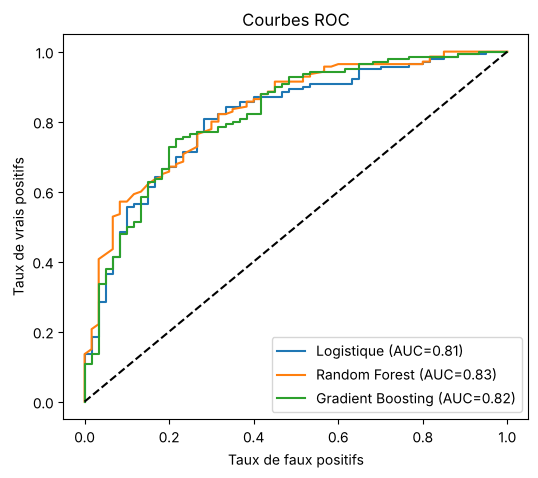

In [13]:
plt.figure(figsize=(6,5))
for n, p in probas.items():
    fpr, tpr, _ = roc_curve(y_te, p)
    plt.plot(fpr, tpr, label=f"{n} (AUC={roc_auc_score(y_te,p):.2f})")
plt.plot([0,1],[0,1],"k--")
plt.xlabel("Taux de faux positifs"); plt.ylabel("Taux de vrais positifs")
plt.title("Courbes ROC"); plt.legend(); plt.show()

### Importance des variables

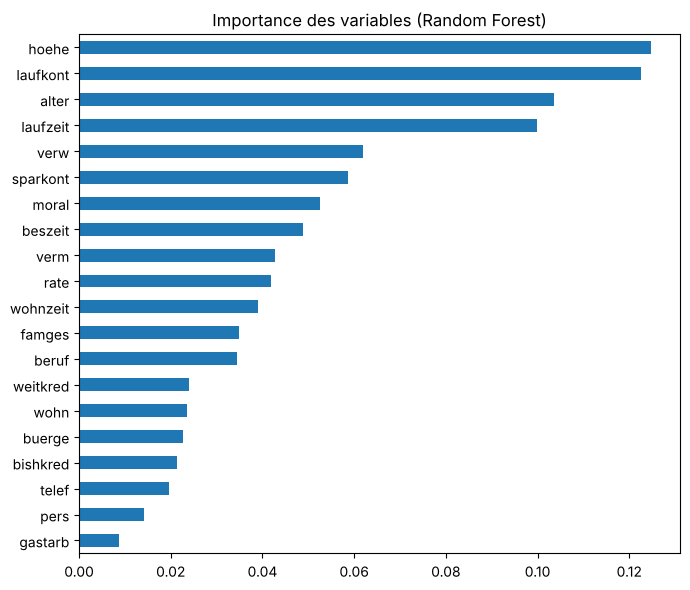

In [14]:
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot.barh(figsize=(7,6), title="Importance des variables (Random Forest)")
plt.tight_layout(); plt.show()

### Seuil optimal (matrice de coût)

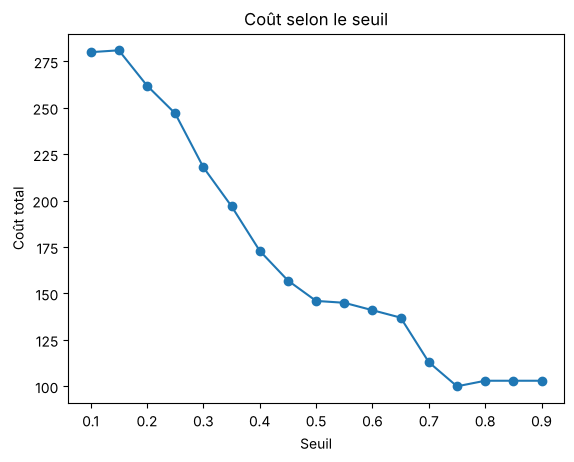

Seuil optimal : 0.75


In [15]:
p = probas["Gradient Boosting"]
seuils = np.arange(0.1, 0.95, 0.05)
couts = [5*((p>=t)&(y_te==0)).sum() + 1*((p<t)&(y_te==1)).sum() for t in seuils]

plt.plot(seuils, couts, marker="o")
plt.xlabel("Seuil"); plt.ylabel("Coût total"); plt.title("Coût selon le seuil"); plt.show()
print("Seuil optimal :", round(seuils[int(np.argmin(couts))], 2))

### Matrice de corrélation

In [16]:
corr = df.corr()
corr.round(2)

,laufkont,laufzeit,moral,verw,hoehe,sparkont,beszeit,rate,famges,buerge,...,verm,alter,weitkred,wohn,bishkred,beruf,pers,telef,gastarb,kredit
laufkont,1.00,-0.07,0.19,0.03,-0.04,0.22,0.11,-0.01,0.04,-0.13,...,-0.03,0.06,0.07,0.02,0.08,0.04,0.01,0.07,0.04,0.35
laufzeit,-0.07,1.00,-0.08,0.15,0.62,0.05,0.06,0.07,0.01,-0.02,...,0.30,-0.04,-0.06,0.15,-0.01,0.21,0.02,0.16,0.13,-0.21
moral,0.19,-0.08,1.00,-0.09,-0.06,0.04,0.14,0.04,0.04,-0.04,...,-0.05,0.15,0.16,0.06,0.44,0.01,-0.01,0.05,-0.03,0.23
verw,0.03,0.15,-0.09,1.00,0.07,-0.02,0.02,0.05,0.00,-0.02,...,0.01,-0.00,-0.10,0.01,0.05,0.01,0.03,0.08,0.11,-0.02
hoehe,-0.04,0.62,-0.06,0.07,1.00,0.06,-0.01,-0.27,-0.02,-0.03,...,0.31,0.03,-0.07,0.13,0.02,0.29,-0.02,0.28,0.03,-0.15
sparkont,0.22,0.05,0.04,-0.02,0.06,1.00,0.12,0.02,0.02,-0.11,...,0.02,0.08,0.00,0.01,-0.02,0.01,-0.03,0.09,-0.01,0.18
beszeit,0.11,0.06,0.14,0.02,-0.01,0.12,1.00,0.13,0.11,-0.01,...,0.09,0.26,-0.01,0.12,0.13,0.10,-0.10,0.06,0.02,0.12
rate,-0.01,0.07,0.04,0.05,-0.27,0.02,0.13,1.00,0.12,-0.01,...,0.05,0.06,0.01,0.09,0.02,0.10,0.07,0.01,0.09,-0.07
famges,0.04,0.01,0.04,0.00,-0.02,0.02,0.11,0.12,1.00,0.05,...,-0.01,0.01,-0.03,0.10,0.06,-0.01,-0.12,0.03,-0.07,0.09
buerge,-0.13,-0.02,-0.04,-0.02,-0.03,-0.11,-0.01,-0.01,0.05,1.00,...,-0.16,-0.03,-0.04,-0.07,-0.03,-0.06,-0.02,-0.08,-0.14,0.03


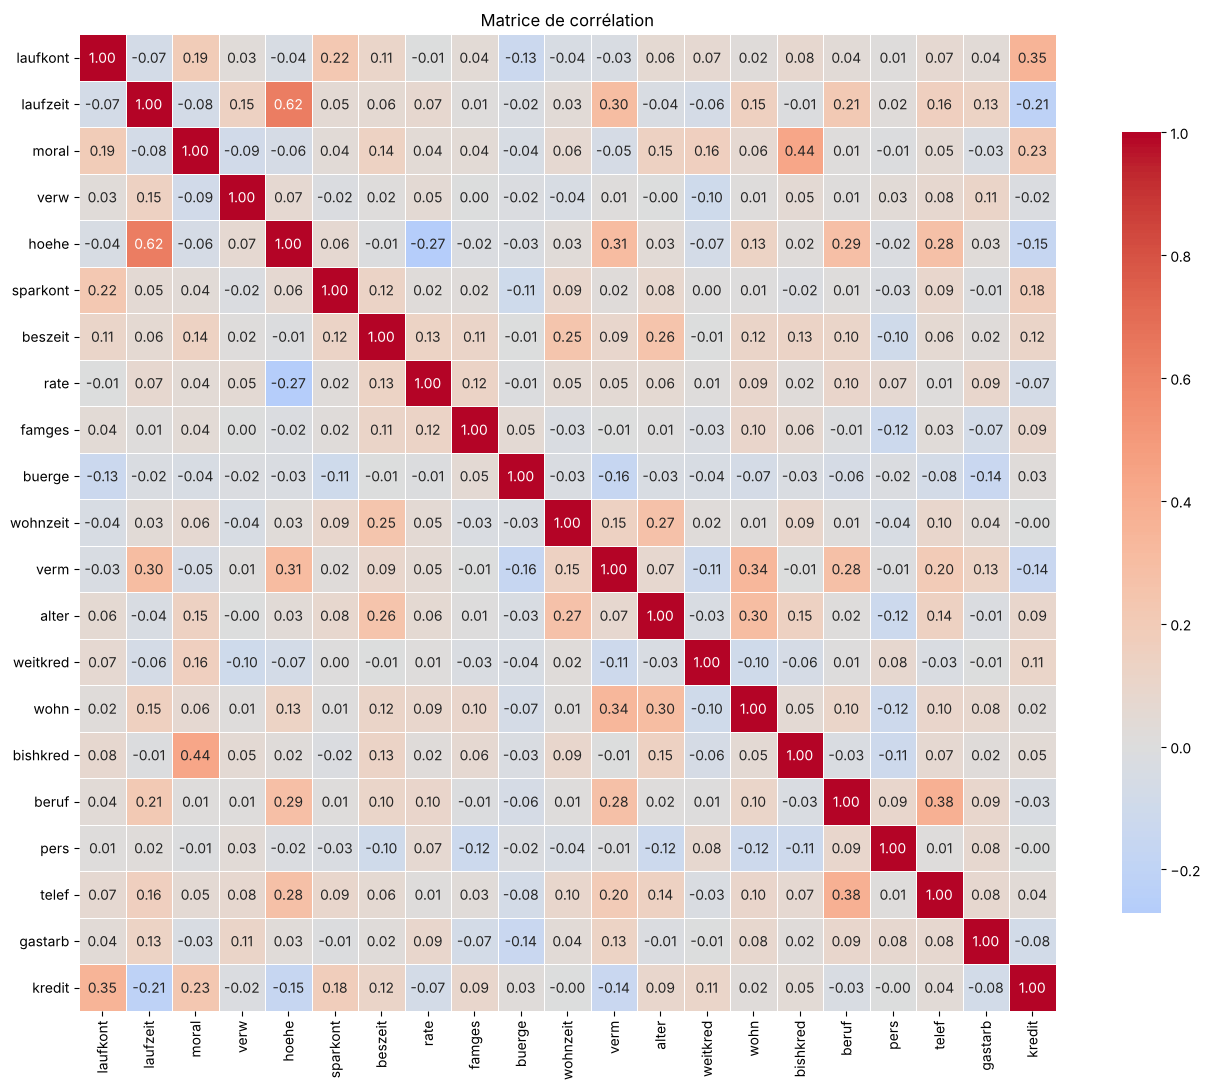

In [17]:
import seaborn as sns

plt.figure(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()

### Corrélation avec la cible

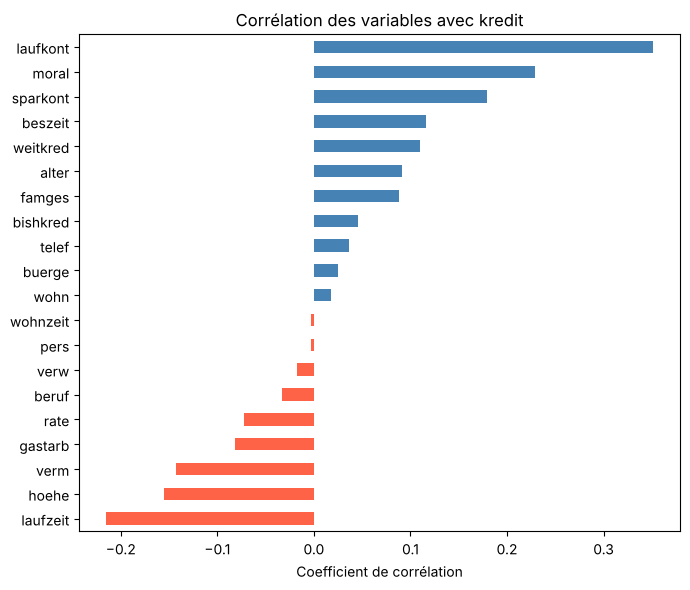

laufzeit   -0.215
hoehe      -0.155
verm       -0.143
gastarb    -0.082
rate       -0.072
beruf      -0.033
verw       -0.018
pers       -0.003
wohnzeit   -0.003
wohn        0.018
buerge      0.025
telef       0.036
bishkred    0.046
famges      0.088
alter       0.091
weitkred    0.110
beszeit     0.116
sparkont    0.179
moral       0.229
laufkont    0.351
Name: kredit, dtype: float64


In [18]:
cor_cible = corr["kredit"].drop("kredit").sort_values()

plt.figure(figsize=(7, 6))
cor_cible.plot.barh(color=["tomato" if v < 0 else "steelblue" for v in cor_cible])
plt.title("Corrélation des variables avec kredit")
plt.xlabel("Coefficient de corrélation")
plt.tight_layout()
plt.show()

print(cor_cible.round(3))

### Paires fortement corrélées

In [19]:
paires = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
              .stack()
              .reset_index())
paires.columns = ["Variable 1", "Variable 2", "Corrélation"]
paires[paires["Corrélation"].abs() > 0.3].sort_values("Corrélation", key=abs, ascending=False)

,Variable 1,Variable 2,Corrélation
25,laufzeit,hoehe,0.624988
57,moral,bishkred,0.437066
354,beruf,telef,0.383022
20,laufkont,kredit,0.350847
245,verm,wohn,0.342969
95,hoehe,verm,0.311602
32,laufzeit,verm,0.303971
266,alter,wohn,0.303346
